<a href="https://colab.research.google.com/github/TBDA-Classes/2026G3/blob/main/TBDA_F3_2_Zone_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F3.2 – Zone comparison, normalised per device
Goal: for each load type, compare the zones on the same scale (per device) to spot a zone consuming abnormally more than its neighbours. Years: 2021–2022. Data: cedint_f1_hourly_clean v0.3. Follows P9 (F5.3).

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")
df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])
print("Dimensions:", df.shape)

/tmp/ipykernel_492/2950936313.py:4: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")


Dimensions: (470680, 50)


In [5]:
devices_table = df.groupby(["zone", "load_type"])["n_devices"].agg(lambda s: sorted(s.unique()))
print(devices_table)
print()
print("Era values:", df["era"].unique())

zone  load_type      
NE    HVAC                [2]
      Plugs & Sockets    [38]
NW    Emerg. Lighting    [24]
      HVAC               [11]
      Hand Dryer          [3]
      Lighting           [77]
      Plugs & Sockets    [73]
      RACK                [1]
SE    Emerg. Lighting    [14]
      HVAC               [12]
      Lighting           [48]
      Plugs & Sockets    [75]
      Projector           [1]
SW    Emerg. Lighting    [18]
      Hand Dryer          [2]
      Lighting           [92]
      Plugs & Sockets    [38]
      RACK                [1]
Name: n_devices, dtype: object

Era values: ['hourly' 'minute']


In [9]:
years = [2021, 2022]

def compare_zone(load, label, df=df, year_filter=years):
    d = df[
        (df["load_type"] == load) &
        (df["timestamp_local"].dt.year.isin(year_filter)) &
        (df["usable_for_model"] == 1)
    ].dropna(subset=["energy_wh_model"]).copy()
    d["energy_per_device"] = d["energy_wh_model"] / d["n_devices"]
    comp = d.groupby("zone").agg(
        mean_raw=("energy_wh_model", "mean"),
        n_devices=("n_devices", "first"),
        mean_per_device=("energy_per_device", "mean"),
        hours=("energy_per_device", "count"),
    )
    comp["share_vs_floor"] = comp["mean_per_device"] / comp["mean_per_device"].mean()
    print(f"=== {label} ===")
    print(comp.round(2))
    print()
    return comp

def plot_comp(comp, title):
    comp["mean_per_device"].plot(kind="bar", figsize=(7, 4), color="steelblue")
    plt.axhline(comp["mean_per_device"].mean(), color="red", linestyle="--", linewidth=1, label="Floor mean")
    plt.title(title)
    plt.xlabel("Zone")
    plt.ylabel("Mean hourly energy per device (Wh)")
    plt.legend()
    plt.show()

=== Plugs & Sockets (2021–2022) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NE      179.25         38             4.72  17135            0.56
NW     1276.57         73            17.49  17135            2.07
SE      293.18         75             3.91  15868            0.46
SW      290.01         38             7.63  13884            0.90



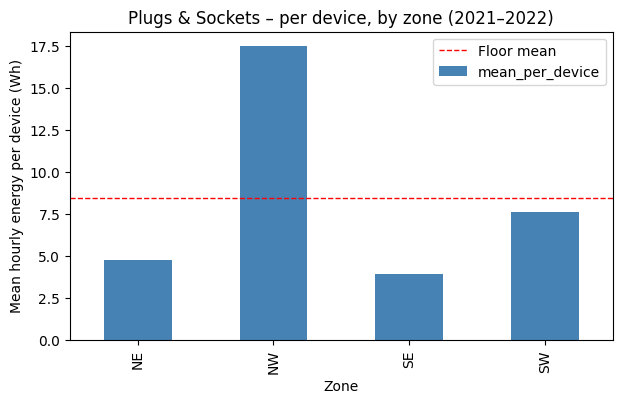

In [10]:
comp_plugs = compare_zone("Plugs & Sockets", "Plugs & Sockets (2021–2022)")
plot_comp(comp_plugs, "Plugs & Sockets – per device, by zone (2021–2022)")

=== Lighting (2021–2022) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NW      183.93         77             2.39  17132            1.47
SE       50.44         48             1.05  16033            0.65
SW      133.00         92             1.45  14055            0.89



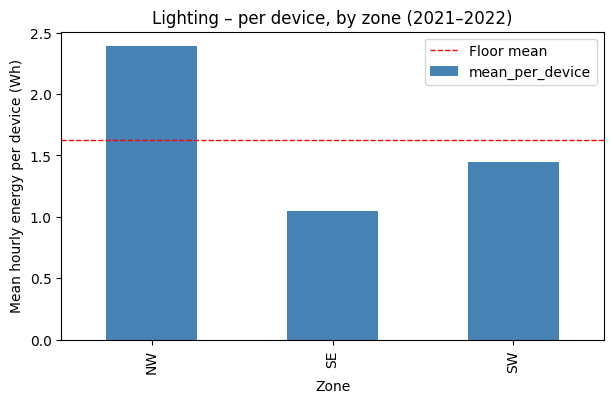

In [11]:
comp_light = compare_zone("Lighting", "Lighting (2021–2022)")
plot_comp(comp_light, "Lighting – per device, by zone (2021–2022)")

=== HVAC (2021–2022) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NE        3.03          2             1.52  17135            0.29
NW       93.12         11             8.47  15985            1.62
SE       68.66         12             5.72  15782            1.09



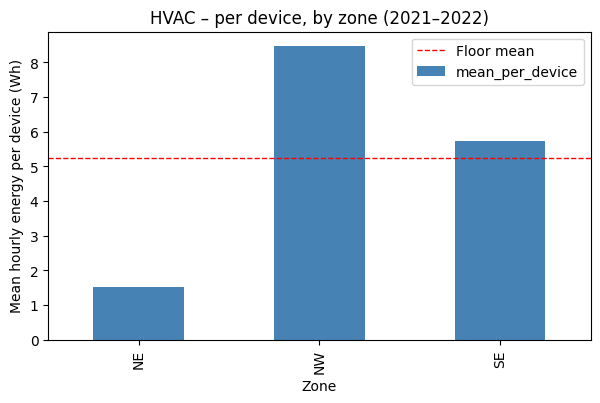

In [12]:
comp_hvac = compare_zone("HVAC", "HVAC (2021–2022)")
plot_comp(comp_hvac, "HVAC – per device, by zone (2021–2022)")

In [13]:
quality = df[df["timestamp_local"].dt.year.isin(years)].groupby(["zone", "load_type"]).agg(
    share_usable=("usable_for_model", "mean"),
    share_neg_large=("flag_neg_large", "mean"),
    share_low_coverage=("flag_low_coverage", "mean"),
    share_reversed=("reversed_sign", "mean"),
)
print("Share of flagged hours (2021–2022) — check comparability before interpreting differences:")
print(quality.round(3))

Share of flagged hours (2021–2022) — check comparability before interpreting differences:
                      share_usable  share_neg_large  share_low_coverage  \
zone load_type                                                            
NE   HVAC                      1.0              0.0                 0.0   
     Plugs & Sockets           1.0              0.0                 0.0   
NW   Emerg. Lighting           1.0              0.0                 0.0   
     HVAC                      1.0              0.0                 0.0   
     Hand Dryer                1.0              0.0                 0.0   
     Lighting                  1.0              0.0                 0.0   
     Plugs & Sockets           1.0              0.0                 0.0   
     RACK                      1.0              0.0                 0.0   
SE   Emerg. Lighting           1.0              0.0                 0.0   
     HVAC                      1.0              0.0                 0.0   
     Light

=== RACK, common period (2021) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NW      174.71          1           174.71   8759            0.77
SW      280.86          1           280.86   6914            1.23



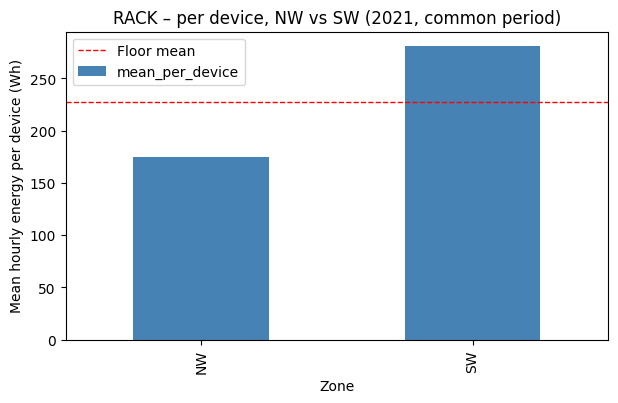

In [14]:
# SW RACK counter stops in Dec 2021 — restrict the comparison to the common period
comp_rack = compare_zone("RACK", "RACK, common period (2021)", year_filter=[2021])
plot_comp(comp_rack, "RACK – per device, NW vs SW (2021, common period)")

In [15]:
comp_emerg = compare_zone("Emerg. Lighting", "Emergency Lighting (2021–2022)")
comp_dryer = compare_zone("Hand Dryer", "Hand Dryer (2021–2022)")

=== Emergency Lighting (2021–2022) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NW       12.82         24             0.53  15986            1.27
SE        1.66         14             0.12  15840            0.28
SW       11.02         18             0.61  13756            1.45

=== Hand Dryer (2021–2022) ===
      mean_raw  n_devices  mean_per_device  hours  share_vs_floor
zone                                                             
NW        3.06          3             1.02  17133            0.22
SW       16.36          2             8.18  14546            1.78



In [16]:
summary = []
for label, comp in [("Plugs & Sockets", comp_plugs), ("Lighting", comp_light),
                    ("HVAC", comp_hvac), ("RACK 2021", comp_rack)]:
    for zone, row in comp.iterrows():
        summary.append({
            "load": label, "zone": zone,
            "mean_per_device_wh": round(row["mean_per_device"], 1),
            "share_vs_floor": round(row["share_vs_floor"], 2),
        })
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

           load zone  mean_per_device_wh  share_vs_floor
Plugs & Sockets   NE                 4.7            0.56
Plugs & Sockets   NW                17.5            2.07
Plugs & Sockets   SE                 3.9            0.46
Plugs & Sockets   SW                 7.6            0.90
       Lighting   NW                 2.4            1.47
       Lighting   SE                 1.1            0.65
       Lighting   SW                 1.4            0.89
           HVAC   NE                 1.5            0.29
           HVAC   NW                 8.5            1.62
           HVAC   SE                 5.7            1.09
      RACK 2021   NW               174.7            0.77
      RACK 2021   SW               280.9            1.23


F3.2 – Zone comparison normalised per device

Objective
Compare the zones for the same load type, normalised per device (n_devices), to spot a zone
consuming abnormally more than its neighbours. Years 2021–2022, usable_for_model = 1.

Results
– Plugs & Sockets (all 4 zones): NW = 17.5 Wh/device/h (2.07x floor mean) vs NE 4.7,
  SW 7.6, SE 3.9. NW stands out clearly.
– Lighting (NW/SE/SW): NW 2.4 Wh/device (1.47x) > SW 1.4 > SE 1.1.
– HVAC (NE/NW/SE): NW 8.5 Wh/device (1.62x) > SE 5.7 > NE 1.5 (0.29x).
– RACK (common period 2021): SW 280.9 > NW 174.7 Wh/device.
– Hand Dryer: SW 8.2 vs NW 1.0 Wh/device. Emerg. Lighting: SE 0.12 vs NW 0.53, SW 0.61.
– Quality: all comparisons on clean hours only; SE Projector excluded (0% usable, dead series);
  NW Emerg. Lighting fully reversed-sign but corrected in energy_wh_model.

Interpretation
1. NW is the heaviest consumer per device across the three main loads (plugs 2.07x,
   lighting 1.47x, HVAC 1.62x). The HVAC part is partly explained: NW is cooling-dominated
   and weather-sensitive (cf. P9, F5.3). The plugs gap (2x) has no obvious driver — it is
   the main SUSPECT zone for the technician: check what is plugged in NW and whether
   some devices draw power outside occupancy hours.
2. NE is uniformly low (HVAC 0.29x, plugs 0.56x) — consistent with a small/low-usage zone.
3. SW leads on RACK and Hand Dryer — RACK is a server load, expected to be high.
4. Differences are NOT data artefacts: quality flags confirm comparability (cell 7).

Limitations
– Normalisation by n_devices only (no floor area or occupant count available).
– HVAC "devices" may not be of the same type/unit capacity across zones.
– NW Emerg. Lighting values are sign-corrected; treated as indicative only.
– RACK comparison restricted to 2021 (SW counter ends Dec 2021).